# Microscopy scan workflow

**Run All** to generate one experiment, optimize its paths and draw every plot
from the same live `history`. Nothing reads saved results or imports workflow
Python files. Edit the single configuration cell and rerun.

**Parameters → generator → command → instrument → realization → metrics → loss → grid search.**

The optional `Optimization_Benchmark.ipynb` reuses the definitions and configuration
in this notebook; it contains only the advanced search comparison.


In [ ]:
from dataclasses import dataclass, replace
from itertools import product
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree


## Data passed between modules

`Trajectory` holds positions, increasing times, acquisition mask and exposure per
event. Arrays are copied and read-only. `Realization` holds the realized trajectory.
Positions use FOV units, time seconds and exposure normalized dose units. Commands
are linear between knots; extra motion knots are not additional acquisitions.


In [ ]:
@dataclass(frozen=True)
class Trajectory:
    """Positions (N, 2), time (N,) in consistent length units and seconds.

    Commands are linearly interpolated between knots. acquire marks measurement
    events (default: all knots); intervening motion is not a measurement.
    """
    xy: np.ndarray
    t: np.ndarray
    acquire: np.ndarray | None = None
    exposure: np.ndarray | None = None

    def __post_init__(self):
        xy, t = np.array(self.xy, dtype=float, copy=True), np.array(self.t, dtype=float, copy=True)
        if t.ndim != 1 or len(t) < 2 or xy.shape != (len(t), 2):
            raise ValueError('Expected xy=(N,2), t=(N,), N>=2')
        if not np.isfinite(xy).all() or not np.isfinite(t).all() or np.any(np.diff(t) <= 0):
            raise ValueError('Positions and times must be finite; times strictly increasing')
        xy.setflags(write=False)
        t.setflags(write=False)
        object.__setattr__(self, 'xy', xy)
        object.__setattr__(self, 't', t)
        acquire = np.ones(len(t), dtype=bool) if self.acquire is None else np.array(self.acquire, dtype=bool, copy=True)
        if acquire.shape != t.shape:
            raise ValueError('Acquisition mask must have shape (N,)')
        acquire.setflags(write=False)
        object.__setattr__(self, 'acquire', acquire)
        exposure = acquire.astype(float) if self.exposure is None else np.array(self.exposure, dtype=float, copy=True)
        if exposure.shape != t.shape or not np.isfinite(exposure).all() or np.any(exposure < 0):
            raise ValueError('Exposure must be finite, nonnegative and have shape (N,)')
        if np.any(exposure[~acquire] != 0) or np.any(exposure[acquire] <= 0):
            raise ValueError('Exposure must be positive exactly at acquisition events')
        exposure.setflags(write=False)
        object.__setattr__(self, 'exposure', exposure)


@dataclass(frozen=True)
class Realization:
    trajectory: Trajectory


## Parameterized generators

Each callable accepts a parameter dictionary and returns a `Trajectory`.


In [ ]:
@dataclass(frozen=True)
class ScanBudget:
    duration: float = 10.0
    samples: int = 1000

    def __post_init__(self):
        if not np.isfinite(self.duration) or self.duration <= 0:
            raise ValueError('Duration must be finite and positive')
        if isinstance(self.samples, bool) or not isinstance(self.samples, int) or self.samples < 3:
            raise ValueError('Samples must be an integer >=3')

    def time(self):
        return np.linspace(0, self.duration, self.samples)


def positive(value, name):
    value = float(value)
    if not np.isfinite(value) or value <= 0:
        raise ValueError(f'{name} must be finite and positive')
    return value


def rotate(xy, angle):
    if not np.isfinite(angle):
        raise ValueError('Orientation must be finite')
    c, s = np.cos(angle), np.sin(angle)
    return xy @ np.array([[c, s], [-s, c]])


def integer(value, name, minimum=1):
    number = positive(value, name)
    if int(number) != number or number < minimum:
        raise ValueError(f'{name} must be an integer >={minimum}')
    return int(number)


def radius_parameter(params):
    radius = positive(params.get('radius', .5), 'radius')
    if radius > .5:
        raise ValueError('Radius must be <=0.5')
    return radius


def polyline(vertices, budget):
    """Uniform arc-length sampling including all connecting moves."""
    xy = np.asarray(vertices, dtype=float)
    arc = np.r_[0, np.cumsum(np.linalg.norm(np.diff(xy, axis=0), axis=1))]
    keep = np.r_[True, np.diff(arc) > 0]
    xy, arc = xy[keep], arc[keep]
    if len(arc) < 2:
        raise ValueError('Polyline must have nonzero length')
    distance = np.linspace(0, arc[-1], budget.samples)
    return Trajectory(np.column_stack([np.interp(distance, arc, xy[:, i]) for i in range(2)]),
                      budget.time())


### Straight strokes

Repeated bidirectional line passes. Parameters: strokes, radius, orientation.


In [ ]:
@dataclass(frozen=True)
class StraightStrokes:
    """Repeated passes along a single centered line, alternating direction."""
    budget: ScanBudget = ScanBudget()

    def __call__(self, params):
        strokes = integer(params.get('strokes', 8), 'strokes')
        radius = radius_parameter(params)
        vertices = [(radius * (-1 if i % 2 == 0 else 1), 0) for i in range(strokes + 1)]
        return polyline(rotate(np.asarray(vertices), params.get('orientation', 0)), self.budget)


### Raster / hatch

Parallel serpentine hatch strokes. Parameters: lines, orientation. Connectors count toward motion.


In [ ]:
@dataclass(frozen=True)
class Raster:
    budget: ScanBudget = ScanBudget()

    def __call__(self, params):
        raw_lines = positive(params.get('lines', 12), 'lines')
        lines = int(raw_lines)
        if lines != raw_lines or lines < 2:
            raise ValueError('Lines must be an integer >=2')
        vertices = []
        for i, y in enumerate(np.linspace(-.5, .5, lines)):
            ends = (-.5, .5) if i % 2 == 0 else (.5, -.5)
            vertices.extend([(ends[0], y), (ends[1], y)])
        xy = np.asarray(vertices)
        arc = np.r_[0, np.cumsum(np.linalg.norm(np.diff(xy, axis=0), axis=1))]
        distance = np.linspace(0, arc[-1], self.budget.samples)
        xy = np.column_stack([np.interp(distance, arc, xy[:, axis]) for axis in range(2)])
        # Fit rotated square inside the same field of view.
        angle = float(params.get('orientation', 0))
        xy = rotate(xy, angle) / (abs(np.cos(angle)) + abs(np.sin(angle)))
        return Trajectory(xy, self.budget.time())


### Pulse lattice

Stationary holds on a serpentine lattice, with blanked transfers. Parameters: rows, columns, radius, dwell_fraction.


In [ ]:
@dataclass(frozen=True)
class PulseLattice:
    """Serpentine lattice with stationary acquisition and blanked transfers.

    dwell_fraction is the fraction of each site block held at the site.
    Pulse events are repeated equal-time acquisition knots, not a beam model.
    """
    budget: ScanBudget = ScanBudget()

    def __call__(self, params):
        rows = integer(params.get('rows', 6), 'rows', 2)
        columns = integer(params.get('columns', 6), 'columns', 2)
        dwell = float(params.get('dwell_fraction', .6))
        if not np.isfinite(dwell) or not 0 < dwell < 1:
            raise ValueError('dwell_fraction must be in (0,1)')
        radius = radius_parameter(params)
        sites = []
        x = np.linspace(-radius, radius, columns)
        for i, y in enumerate(np.linspace(-radius, radius, rows)):
            sites.extend((v, y) for v in (x if i % 2 == 0 else x[::-1]))
        sites = np.asarray(sites)
        if self.budget.samples < 3 * len(sites):
            raise ValueError('Pulse lattice needs at least three samples per site')
        blocks = np.array_split(np.arange(self.budget.samples), len(sites))
        xy = np.empty((self.budget.samples, 2))
        acquire = np.zeros(self.budget.samples, dtype=bool)
        for i, block in enumerate(blocks):
            hold = max(1, min(len(block)-2, int(round(dwell * len(block)))))
            xy[block[:hold]] = sites[i]
            acquire[block[:hold]] = True
            following = sites[min(i+1, len(sites)-1)]
            progress = np.linspace(0, 1, len(block)-hold+1)[1:]
            xy[block[hold:]] = sites[i] + progress[:, None] * (following - sites[i])
        # Last site remains exposed during its remaining stationary samples.
        acquire[blocks[-1]] = True
        return Trajectory(xy, self.budget.time(), acquire)


### Spiral

Archimedean spiral. Parameters: turns, radius, orientation.


In [ ]:
@dataclass(frozen=True)
class Spiral:
    budget: ScanBudget = ScanBudget()

    def __call__(self, params):
        turns = positive(params.get('turns', 8), 'turns')
        radius = positive(params.get('radius', .5), 'radius')
        if radius > .5:
            raise ValueError('Radius must be <=0.5')
        u = np.linspace(0, 1, self.budget.samples)
        theta = 2 * np.pi * turns * u
        xy = radius * u[:, None] * np.column_stack((np.cos(theta), np.sin(theta)))
        return Trajectory(rotate(xy, params.get('orientation', 0)), self.budget.time())


### Closed loops

Repeated circle or ellipse. Parameters: loops, radius, axis_ratio, orientation.


In [ ]:
@dataclass(frozen=True)
class ClosedLoops:
    """Repeated closed circle or ellipse; axis_ratio controls ellipticity."""
    budget: ScanBudget = ScanBudget()

    def __call__(self, params):
        loops = integer(params.get('loops', 6), 'loops')
        radius = radius_parameter(params)
        ratio = positive(params.get('axis_ratio', 1), 'axis_ratio')
        if ratio > 1:
            raise ValueError('axis_ratio must be <=1')
        theta = np.linspace(0, 2*np.pi*loops, self.budget.samples)
        xy = radius * np.column_stack((np.cos(theta), ratio*np.sin(theta)))
        return Trajectory(rotate(xy, params.get('orientation', 0)), self.budget.time())


### Radial / rays

Center to edge and back along equally spaced rays. Parameters: rays, radius, orientation.


In [ ]:
@dataclass(frozen=True)
class RadialRays:
    """Center → edge → center for each equally spaced ray."""
    budget: ScanBudget = ScanBudget()

    def __call__(self, params):
        rays = integer(params.get('rays', 12), 'rays', 2)
        radius = radius_parameter(params)
        angle = float(params.get('orientation', 0))
        vertices = [(0, 0)]
        for theta in np.arange(rays) * (2*np.pi/rays):
            vertices.extend([(radius*np.cos(theta), radius*np.sin(theta)), (0, 0)])
        return polyline(rotate(np.asarray(vertices), angle), self.budget)


### Flowers

Polar rose. Parameters: order, cycles, radius, orientation; odd order has order petals, even order twice order.


In [ ]:
@dataclass(frozen=True)
class Flower:
    """Closed polar rose r=radius*cos(order*theta); repeated full cycles.

    Odd order gives order petals, even order gives twice order petals.
    """
    budget: ScanBudget = ScanBudget()

    def __call__(self, params):
        order = integer(params.get('order', 3), 'order')
        cycles = integer(params.get('cycles', 3), 'cycles')
        radius = radius_parameter(params)
        theta = np.linspace(0, 2*np.pi*cycles, self.budget.samples)
        r = radius * np.cos(order*theta)
        xy = r[:, None] * np.column_stack((np.cos(theta), np.sin(theta)))
        return Trajectory(rotate(xy, params.get('orientation', 0)), self.budget.time())


### Lissajous

Sinusoidal x/y coordinates. Parameters: cycles, ratio, phase.


In [ ]:
@dataclass(frozen=True)
class Lissajous:
    budget: ScanBudget = ScanBudget()

    def __call__(self, params):
        cycles = positive(params.get('cycles', 5), 'cycles')
        ratio = positive(params.get('ratio', 1.4), 'ratio')
        phase = float(params.get('phase', np.pi / 2))
        u = np.linspace(0, 2 * np.pi * cycles, self.budget.samples)
        xy = .5 * np.column_stack((np.sin(u), np.sin(ratio * u + phase)))
        return Trajectory(xy, self.budget.time())


## Instrument

One first-order lag plus constant drift. The ideal substitute has no distortion.
Starts settled at the first position; startup travel is outside the experiment.
`substeps` is only for an optional finer-resolution check. No unused state is stored.


In [ ]:
@dataclass(frozen=True)
class IdealInstrument:
    def __call__(self, command):
        return Realization(command)


@dataclass(frozen=True)
class LagInstrument:
    """Exact first-order response to piecewise linear commands, plus drift.

    Starts settled at the first command. tau is in seconds, drift in length/s.
    Drift represents sample-relative position and is outside the servo loop.
    """
    tau: float = .08
    drift: tuple[float, float] = (.001, -.001)
    substeps: int = 1

    def __post_init__(self):
        if not np.isfinite(self.tau) or self.tau <= 0:
            raise ValueError('tau must be finite and positive')
        if np.shape(self.drift) != (2,) or not np.isfinite(self.drift).all():
            raise ValueError('drift must have two finite components')
        if not isinstance(self.substeps, int) or self.substeps < 1:
            raise ValueError('substeps must be a positive integer')

    def __call__(self, command):
        if self.substeps > 1:
            times = np.concatenate([np.linspace(a, b, self.substeps, endpoint=False)
                                    for a, b in zip(command.t[:-1], command.t[1:])] + [command.t[-1:]])
            xy = np.column_stack([np.interp(times, command.t, command.xy[:, i]) for i in range(2)])
            acquire = np.zeros(len(times), dtype=bool)
            exposure = np.zeros(len(times))
            acquire[::self.substeps] = command.acquire
            exposure[::self.substeps] = command.exposure
            command = Trajectory(xy, times, acquire, exposure)
        servo = np.empty_like(command.xy)
        servo[0] = command.xy[0]
        for i, dt in enumerate(np.diff(command.t), 1):
            velocity = (command.xy[i] - command.xy[i-1]) / dt
            response = -np.expm1(-dt / self.tau)
            servo[i] = (servo[i-1] + response * (command.xy[i-1] - servo[i-1])
                        + velocity * (dt - self.tau * response))
        xy = servo + (command.t - command.t[0])[:, None] * np.asarray(self.drift)
        return Realization(Trajectory(xy, command.t, command.acquire, command.exposure))


## Metrics, comparison rules and loss

Default quality metrics are **RMS distortion** and **physical-radius coverage**.
Motion and exposure metrics support comparison rules and show costs independently.
The loss adds normalized distortion, uncovered fraction and a soft length penalty.
These priorities are illustrative. Speed and acceleration remain hard limits;
command acceleration is a discrete controller metric, not a smooth-corner guarantee.


In [ ]:
def distortion(command, realized):
    actual = realized.trajectory
    if actual.t[0] > command.t[0] or actual.t[-1] < command.t[-1]:
        raise ValueError('Realized times must span the command')
    xy = np.column_stack([np.interp(command.t, actual.t, actual.xy[:, i]) for i in range(2)])
    return {'rms_distortion': float(np.sqrt(np.mean(np.sum((xy-command.xy)**2, axis=1))))}

@dataclass(frozen=True)
class Coverage:
    query_bins: int = 48
    radius: float = .03

    def __post_init__(self):
        if not isinstance(self.query_bins, int) or self.query_bins < 2 or not np.isfinite(self.radius) or self.radius <= 0:
            raise ValueError('Use at least two query bins and a positive finite radius')

    def __call__(self, command, realized):
        acquired = realized.trajectory.xy[realized.trajectory.acquire]
        if not len(acquired):
            raise ValueError('Coverage requires acquisition events')
        axis = (np.arange(self.query_bins)+.5)/self.query_bins-.5
        grid = np.stack(np.meshgrid(axis, axis), axis=-1).reshape(-1, 2)
        distance = cKDTree(acquired).query(grid)[0]
        return {'spatial_coverage': float(np.mean(distance <= self.radius))}

def motion(command, realized):
    actual = realized.trajectory
    values = {'duration': float(actual.t[-1]-actual.t[0]),
              'command_duration': float(command.t[-1]-command.t[0]),
              'acquisition_count': int(actual.acquire.sum()),
              'total_exposure': float(actual.exposure.sum()),
              'command_exposure': float(command.exposure.sum())}
    for prefix, path in [('command', command), ('realized', actual)]:
        dt = np.diff(path.t)
        delta = np.diff(path.xy, axis=0)
        velocity = delta/dt[:, None]
        acceleration = np.diff(velocity, axis=0)/((dt[:-1]+dt[1:])/2)[:, None]
        values[prefix+'_length'] = float(np.linalg.norm(delta, axis=1).sum())
        values[prefix+'_peak_speed'] = float(np.linalg.norm(velocity, axis=1).max())
        values[prefix+'_peak_acceleration'] = float(np.linalg.norm(acceleration, axis=1).max()) if len(acceleration) else 0.
    return values

def exposure_budget(generator, count, dose):
    if not isinstance(count, int) or count < 1 or not np.isfinite(dose) or dose <= 0:
        raise ValueError('Use a positive event count and finite positive exposure')
    def generate(params):
        path = generator(params)
        eligible = np.flatnonzero(path.acquire)
        if len(eligible) < count:
            raise ValueError('Not enough eligible acquisition events')
        selected = eligible[np.linspace(0, len(eligible)-1, count).astype(int)]
        acquire = np.zeros(len(path.t), dtype=bool)
        acquire[selected] = True
        exposure = acquire.astype(float)*dose/count
        return Trajectory(path.xy, path.t, acquire, exposure)
    return generate


## Two workflow operations

`evaluate(params, **components)` runs one candidate. `grid_search(grid, **components)`
returns a list of candidate dictionaries. There are no workflow, trial or result
classes. A record contains both trajectories, metrics, loss and feasibility.


In [ ]:
def evaluate(params, generator, instrument, metrics, objective, constraints=None):
    command = generator(dict(params))
    realized = instrument(command)
    values = {}
    for metric in metrics:
        new = metric(command, realized)
        if values.keys() & new.keys():
            raise ValueError('Metric names must be unique')
        values.update({key: float(value) for key, value in new.items()})
    if not values or not all(np.isfinite(value) for value in values.values()):
        raise ValueError('Metrics must be nonempty and finite')
    loss = float(objective(values))
    if not np.isfinite(loss):
        raise ValueError('Loss must be finite')
    violations = {} if constraints is None else dict(constraints(values))
    if any(not np.isfinite(value) or value < 0 for value in violations.values()):
        raise ValueError('Violations must be finite and nonnegative')
    return {'params': dict(params), 'commanded': command, 'realized': realized,
            'metrics': values, 'loss': loss, 'violations': violations,
            'feasible': not any(value > 0 for value in violations.values())}

def best_trial(records):
    return min((record for record in records if record['feasible']),
               key=lambda record: record['loss'], default=None)

def grid_search(grid, **components):
    if any(not len(axis) for axis in grid.values()):
        raise ValueError('Grid axes cannot be empty')
    return [evaluate(dict(zip(grid, point)), **components) for point in product(*grid.values())]


## One experiment configuration

Edit this cell, then Run All. Lists enumerate discrete choices; tuples bound
continuous parameters. The main grid samples each continuous range at three
levels. All paths share time, event count, dose, instrument and objective.
`selected_family` only chooses the detailed plot; it does not change the experiment.
Pulse transfers stay blanked. Local exposure can differ despite equal total dose.


In [ ]:
config = {
    'duration': 10., 'samples': 1000, 'acquisitions': 200, 'exposure': 1.,
    'target_length': 20., 'distortion_scale': .05, 'length_weight': .1,
    'speed_limit': 4., 'command_acceleration_limit': 200., 'realized_acceleration_limit': 100.,
    'enforce_motion_limits': True, 'lag': .08, 'drift': (.001, -.001),
    'query_bins': 48, 'coverage_radius': .03, 'grid_levels': 3,
    'selected_family': 'lissajous',
}
parameter_spaces = {
    'straight_strokes': {'strokes': [4, 8, 12], 'orientation': (0, np.pi/2), 'radius': (.35, .5)},
    'raster': {'lines': [8, 12, 16], 'orientation': (0, np.pi/2)},
    'pulse_lattice': {'rows': [4, 6, 8], 'columns': [4, 6, 8], 'dwell_fraction': (.35, .75), 'radius': (.35, .5)},
    'spiral': {'turns': [5, 8, 11], 'orientation': (0, np.pi/2), 'radius': (.35, .5)},
    'closed_loops': {'loops': [3, 6, 9], 'axis_ratio': (.5, 1.), 'radius': (.35, .5)},
    'radial_rays': {'rays': [8, 12, 16], 'orientation': (0, np.pi/2), 'radius': (.35, .5)},
    'flower': {'order': [2, 3, 4], 'cycles': [1, 2, 3], 'orientation': (0, np.pi/2), 'radius': (.35, .5)},
    'lissajous': {'cycles': [3, 5, 7], 'ratio': (1.2, 1.6), 'phase': (0, np.pi/2)},
}


In [ ]:
positive_settings = ('duration', 'target_length', 'distortion_scale', 'speed_limit',
                     'command_acceleration_limit', 'realized_acceleration_limit', 'exposure')
if any(not np.isfinite(config[key]) or config[key] <= 0 for key in positive_settings):
    raise ValueError('Time, scales, exposure and limits must be finite and positive')
if not np.isfinite(config['length_weight']) or config['length_weight'] < 0:
    raise ValueError('Length weight must be finite and nonnegative')
if not isinstance(config['grid_levels'], int) or config['grid_levels'] < 2:
    raise ValueError('Use at least two grid levels')
if config['selected_family'] not in parameter_spaces:
    raise ValueError('Unknown selected family')
for parameters in parameter_spaces.values():
    for axis in parameters.values():
        if not len(axis) or not np.isfinite(axis).all():
            raise ValueError('Parameter choices must be finite and nonempty')
        if isinstance(axis, tuple) and (len(axis) != 2 or axis[0] >= axis[1]):
            raise ValueError('Continuous bounds must be increasing pairs')

budget = ScanBudget(config['duration'], config['samples'])
model = LagInstrument(tau=config['lag'], drift=config['drift'])
metric_functions = (distortion, Coverage(config['query_bins'], config['coverage_radius']), motion)
generators = {
    'straight_strokes': StraightStrokes(budget), 'raster': Raster(budget),
    'pulse_lattice': PulseLattice(budget), 'spiral': Spiral(budget),
    'closed_loops': ClosedLoops(budget), 'radial_rays': RadialRays(budget),
    'flower': Flower(budget), 'lissajous': Lissajous(budget),
}
if generators.keys() != parameter_spaces.keys():
    raise ValueError('Each generator needs a matching parameter space')

def quality(metrics):
    return (metrics['rms_distortion']/config['distortion_scale'] + 1-metrics['spatial_coverage']
            + config['length_weight']*(metrics['command_length']/config['target_length']-1)**2)

def comparison_rules(metrics):
    def equality(value, target):
        return max(0., abs(value/target-1)-1e-10)
    def excess(value, target):
        return max(0., value/target-1-1e-10)
    checks = {'duration': equality(metrics['duration'], config['duration']),
              'command_duration': equality(metrics['command_duration'], config['duration']),
              'acquisitions': equality(metrics['acquisition_count'], config['acquisitions']),
              'exposure': equality(metrics['total_exposure'], config['exposure']),
              'command_exposure': equality(metrics['command_exposure'], config['exposure'])}
    if config['enforce_motion_limits']:
        for prefix in ('command', 'realized'):
            checks[prefix+'_speed'] = excess(metrics[prefix+'_peak_speed'], config['speed_limit'])
            checks[prefix+'_acceleration'] = excess(metrics[prefix+'_peak_acceleration'], config[prefix+'_acceleration_limit'])
    return checks

components = {
    name: {'generator': exposure_budget(generator, config['acquisitions'], config['exposure']),
           'instrument': model, 'metrics': metric_functions, 'objective': quality, 'constraints': comparison_rules}
    for name, generator in generators.items()
}
grids = {name: {key: list(axis) if isinstance(axis, list) else list(np.linspace(*axis, config['grid_levels']))
                for key, axis in parameters.items()} for name, parameters in parameter_spaces.items()}


## Generate → distort → score → optimize

`history` is the only experiment dataset: baseline and grid records for all eight
families. Every subsequent plot derives from it. Baselines are diagnostic records;
search winners are selected only from feasible grid candidates.


In [ ]:
history = []
for name in components:
    baseline = evaluate({}, **components[name])
    history.append({**baseline, 'family': name, 'role': 'baseline', 'method': 'baseline', 'seed': None})
    candidates = grid_search(grids[name], **components[name])
    history.extend({**record, 'family': name, 'role': 'search', 'method': 'grid', 'seed': None}
                   for record in candidates)

print(f"{'Family':18s} {'Calls':>6s} {'Feasible':>8s} {'Best loss':>10s}")
for name in components:
    records = [record for record in history if record['family'] == name and record['role'] == 'search']
    winner = best_trial(records)
    text = 'none' if winner is None else f"{winner['loss']:.4f}"
    print(f"{name:18s} {len(records):6d} {sum(r['feasible'] for r in records):8d} {text:>10s}")
selected_name = config['selected_family']
selected_baseline = next(record for record in history if record['family'] == selected_name and record['role'] == 'baseline')
selected_best = best_trial([record for record in history if record['family'] == selected_name and record['role'] == 'search'])
print()
print('Full sequence:', type(selected_baseline['commanded']).__name__, '→',
      type(selected_baseline['realized']).__name__, '→', selected_baseline['metrics'], '→ loss', selected_baseline['loss'])
if selected_best:
    print('Optimized parameters:', selected_best['params'])


Family              Calls Feasible  Best loss
straight_strokes       27       21     1.4696
raster                  9        7     1.6962
pulse_lattice          81       50     1.6028
spiral                 27       27     1.7369
closed_loops           27       27     1.7712
radial_rays            27       15     1.7030
flower                 81       81     1.4482
lissajous              27       24     2.2615

Full sequence: Trajectory → Realization → {'rms_distortion': 0.14555167994895532, 'spatial_coverage': 0.4470486111111111, 'duration': 10.0, 'command_duration': 10.0, 'acquisition_count': 200.0, 'total_exposure': 1.0, 'command_exposure': 1.0, 'command_length': 18.23294186707773, 'command_peak_speed': 2.6841618412398867, 'command_peak_acceleration': 10.807394861800866, 'realized_length': 17.267309230189465, 'realized_peak_speed': 2.557507847123188, 'realized_peak_acceleration': 17.37185221735357} → loss 3.4647656114792764
Optimized parameters: {'cycles': 3, 'ratio': np.float64(1.2

## Selected family: before/after and parameter-loss map

The upper panels compare the commanded and realized paths before and after optimization. The lower-left panel shows position error over time. Baselines can violate motion limits.

**How to read the lower-right heatmap:**

- The horizontal and vertical axes vary two path parameters.
- Other searched parameters stay fixed at the best feasible candidate’s values; the title lists these held-constant values. If no feasible candidate exists, the reference uses the candidate with the least total violation.
- Each cell is one evaluated parameter combination. Its number and color show the quality loss; **lower is better**. Gray cells labeled “Rejected” failed the comparison rules.
- This is a slice of parameter space, not an image of the sample and not the entire search landscape.

For the default **Lissajous** family, the horizontal axis is cycle count and the vertical axis is frequency ratio. Phase stays fixed at the best candidate’s phase. The map therefore answers: “At this phase, which cycle count and frequency ratio give the lowest loss?”


Loss map varies cycles and ratio; held constant: phase = 0 rad.
Each cell is an evaluated parameter combination; gray cells failed comparison rules.


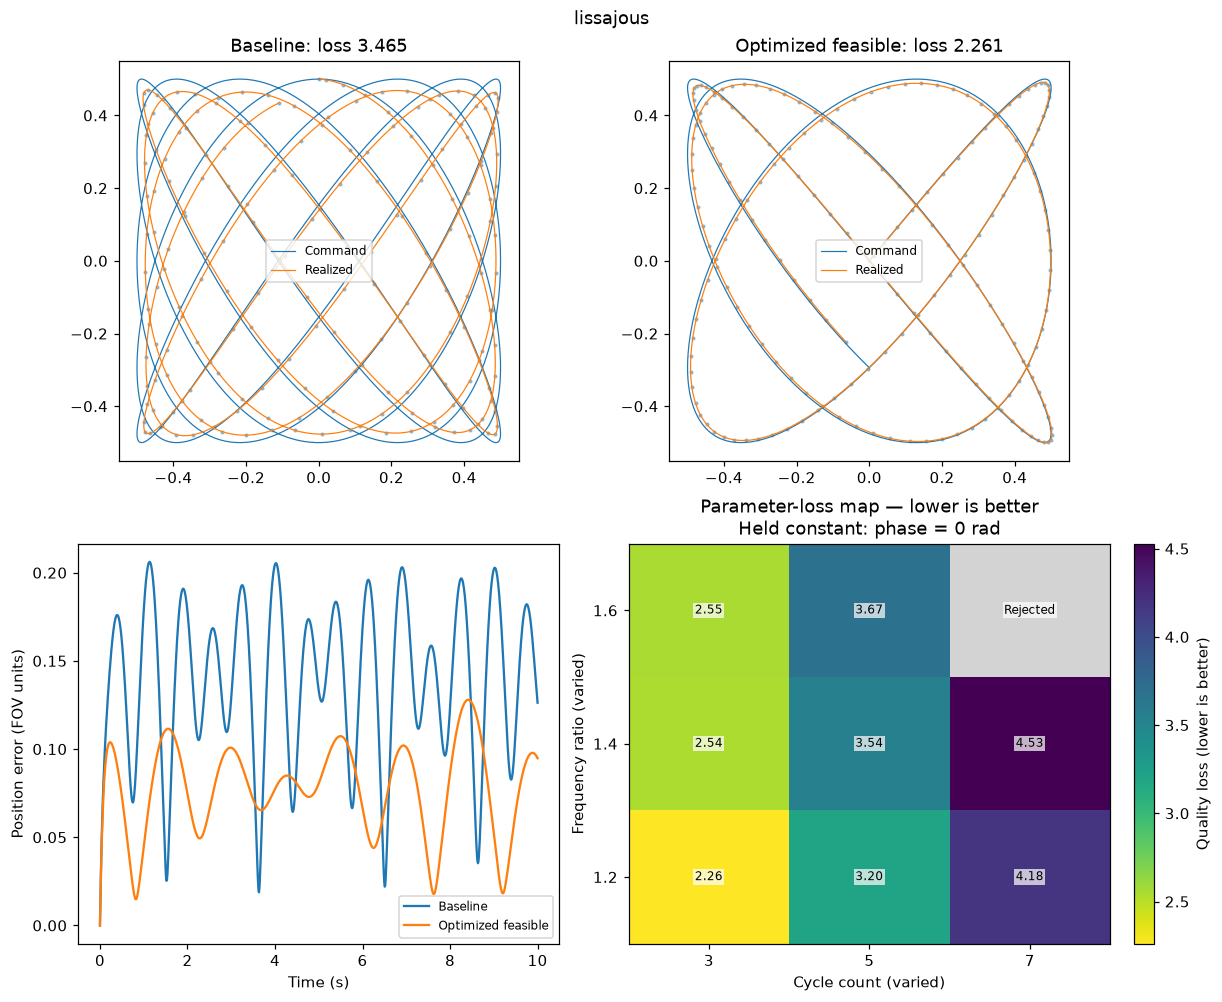

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)
for ax, record, title in zip(axes[0], [selected_baseline, selected_best], ['Baseline', 'Optimized feasible']):
    if record is None:
        ax.text(.5, .5, 'No feasible candidate', ha='center', transform=ax.transAxes)
        continue
    actual = record['realized'].trajectory
    ax.plot(*record['commanded'].xy.T, lw=.8, label='Command')
    ax.plot(*actual.xy.T, lw=.8, label='Realized')
    ax.scatter(*actual.xy[actual.acquire].T, s=3, alpha=.4)
    ax.set(title=f"{title}: loss {record['loss']:.3f}" + ('' if record['feasible'] else ' (infeasible)'),
           aspect='equal', xlim=(-.55, .55), ylim=(-.55, .55))
    ax.legend(fontsize=8)
    aligned = np.column_stack([np.interp(record['commanded'].t, actual.t, actual.xy[:, i]) for i in range(2)])
    error = np.linalg.norm(aligned-record['commanded'].xy, axis=1)
    axes[1, 0].plot(record['commanded'].t, error, label=title)
axes[1, 0].set(xlabel='Time (s)', ylabel='Position error (FOV units)')
axes[1, 0].legend(fontsize=8)
records = [r for r in history if r['family'] == selected_name and r['role'] == 'search']
names = list(grids[selected_name])
xname, yname = names[:2]
reference = selected_best or min(records, key=lambda r: sum(r['violations'].values()))
fixed = {key: reference['params'][key] for key in names[2:]}
xs, ys = grids[selected_name][xname], grids[selected_name][yname]
landscape = np.full((len(ys), len(xs)), np.nan)
for record in records:
    if record['feasible'] and all(record['params'][key] == value for key, value in fixed.items()):
        landscape[ys.index(record['params'][yname]), xs.index(record['params'][xname])] = record['loss']
cmap = plt.get_cmap('viridis_r').copy()
cmap.set_bad('lightgray')
image = axes[1, 1].imshow(np.ma.masked_invalid(landscape), origin='lower', aspect='auto', cmap=cmap)
axes[1, 1].set_xticks(range(len(xs)), [f'{x:.3g}' for x in xs])
axes[1, 1].set_yticks(range(len(ys)), [f'{y:.3g}' for y in ys])
labels = {'cycles': 'Cycle count', 'ratio': 'Frequency ratio', 'phase': 'Phase (rad)',
          'orientation': 'Orientation (rad)', 'radius': 'Radius (FOV units)'}
held = ', '.join(f"{key} = {value:.3g}" + (' rad' if key in ('phase', 'orientation') else '')
                 for key, value in fixed.items()) or 'none (both searched parameters vary)'
axes[1, 1].set(xlabel=labels.get(xname, xname.replace('_', ' '))+' (varied)',
               ylabel=labels.get(yname, yname.replace('_', ' '))+' (varied)',
               title='Parameter-loss map — lower is better\nHeld constant: '+held)
for row in range(len(ys)):
    for col in range(len(xs)):
        value = landscape[row, col]
        text = f'{value:.2f}' if np.isfinite(value) else 'Rejected'
        axes[1, 1].text(col, row, text, ha='center', va='center', fontsize=8,
                       bbox={'facecolor': 'white', 'alpha': .7, 'edgecolor': 'none', 'pad': 1})
fig.colorbar(image, ax=axes[1, 1], label='Quality loss (lower is better)')
fig.suptitle(selected_name.replace('_', ' '))
plt.show()
print(f'Loss map varies {xname} and {yname}; held constant: {held}.')
print('Each cell is an evaluated parameter combination; gray cells failed comparison rules.')


## Component substitution: checking that modules are independent

This section demonstrates **extensibility, not optimization**. Each example swaps
one module and runs the same evaluation function, without rewriting the workflow.

| Example | What changes | What it demonstrates |
|---|---|---|
| Generator | Use a spiral instead of the selected path family | Another path generator can use the same instrument and evaluator. |
| Instrument | Use an ideal instrument instead of lag and drift | Another instrument model can use the same commanded path and evaluator. Its trajectory distortion should be zero. |
| Evaluator | Measure endpoint error instead of the usual metrics | A new quality function can be plugged into the same path and instrument workflow. |

The first two examples retain the usual quality function and comparison rules.
The endpoint-only example uses its own loss and disables those rules because they
require metrics it does not return. Endpoint error is only an interface example,
not a complete measure of imaging quality. The example losses are not a ranking
of which replacement is better.


In [ ]:
reference_params = selected_best['params'] if selected_best else {}
base_components = components[selected_name]
spiral_example = evaluate({}, **{**base_components, 'generator': components['spiral']['generator']})
ideal_example = evaluate(reference_params, **{**base_components, 'instrument': IdealInstrument()})
def endpoint_error(command, realized):
    return {'endpoint_error': float(np.linalg.norm(command.xy[-1]-realized.trajectory.xy[-1]))}
metric_example = evaluate(reference_params, **{**base_components, 'metrics': (endpoint_error,),
    'objective': lambda m: m['endpoint_error'], 'constraints': None})
print('Generator replacement loss:', spiral_example['loss'])
print('Ideal instrument distortion:', ideal_example['metrics']['rms_distortion'])
print('Replacement metric:', metric_example['metrics'])
assert ideal_example['metrics']['rms_distortion'] == 0


Generator replacement loss: 2.710862325375526
Ideal instrument distortion: 0.0
Replacement metric: {'endpoint_error': 0.09480980914534623}
